# 🌦️ Open-Meteo Global High-Resolution Weather & Reanalysis Wrapper Demonstration
### Multi-Model Forecasts (ECMWF IFS 9km, GFS, ICON) & Climatology (1940–present) for East Africa
**Focus Case Study:** Dedan Kimathi University of Technology (DeKUT), Nyeri, Kenya (`-0.398° N, 36.958° E`, Elevation ~1,780m)

---

## 📌 Executive Summary
**Open-Meteo** is an open-source, zero-key global weather API that aggregates and harmonizes national meteorological and climate reanalysis datasets across the world's leading weather centers:
1. **World-Leading Numerical Weather Prediction (NWP) Models:**
   - **ECMWF IFS (9 km):** The European Centre for Medium-Range Weather Forecasts operational global model.
   - **NOAA GFS (13 km / 25 km):** The US National Weather Service Global Forecast System.
   - **DWD ICON (11 km):** Germany's Deutscher Wetterdienst Icosahedral Nonhydrostatic model.
   - **Météo-France ARPEGE (25 km):** France's operational global model.
2. **Comprehensive Meteorological & Soil Suite:**
   - **Surface Meteorology:** Air temperature, relative humidity, dew point, feels-like temperature.
   - **Hydrology & Clouds:** Total precipitation, rain, convective showers, rain probability, cloud cover at low/mid/high levels.
   - **Wind Dynamics:** 10m wind speed, direction, 3-second peak gusts, and 100m wind turbine hub height speeds.
   - **Agricultural Soil Profile:** Volumetric soil moisture and soil temperature across 4 vertical depth layers (0–7cm, 7–28cm, 28–100cm, 100–255cm).
   - **Evapotranspiration:** Reference potential evapotranspiration ($ET_0$) calculated via the **FAO-56 Penman-Monteith** standard equation.
   - **WMO Weather Interpretation:** Numeric codes translated into standard descriptions and weather icons.
3. **Historical Reach & Operational Horizons:**
   - **Historical Archive:** Continuous hourly climate reanalysis from **1940 to present** (ERA5 / ERA5-Land).
   - **Operational Forecasts:** Rolling hourly forecasts up to **16 days forward**.

### Zero-Key Architecture
Through `masharikiweather.wrappers.open_meteo`, users can query global weather data with **zero API keys, zero registration, and few lines of code**, backed by local **Apache Parquet caching** for sub-millisecond retrieval.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set clean scientific plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

# Import MasharikiWeather Open-Meteo wrapper components
from masharikiweather import (
    OpenMeteo,
    query_open_meteo,
    query_open_meteo_forecast,
    query_open_meteo_soil,
    search_open_meteo_parameters,
    list_open_meteo_parameters,
    decode_weather_code,
    get_open_meteo_metadata,
)

# Reference Site Coordinates: Dedan Kimathi University of Technology (DeKUT), Nyeri, Kenya
DEKUT_NYERI_LAT = -0.398
DEKUT_NYERI_LON = 36.958

print("MasharikiWeather Open-Meteo Wrapper initialized successfully!")


MasharikiWeather Open-Meteo Wrapper initialized successfully!


## 1. Parameter Discovery & Metadata Catalog

Let's inspect the dataset metadata, available meteorological variables, and global forecast models accessible through the wrapper.

In [2]:
# Display official dataset metadata
meta = get_open_meteo_metadata()
print("Service Name     :", meta["service_name"])
print("Provider         :", meta["provider"])
print("Forecast Horizon :", meta["temporal_span"])
print("Licensing        :", meta["licensing"])
print("\nSupported Models:")
for m_code, m_desc in meta["supported_models"].items():
    print(f"  • {m_code:<15}: {m_desc}")

# List all available weather, soil, and radiation parameters
params_df = list_open_meteo_parameters()
display(params_df[["Variable", "Category", "Unit", "Aliases", "Description"]])


Service Name     : Open-Meteo Global Weather & Reanalysis API
Provider         : Open-Meteo GmbH (Germany) open-source weather initiative
Forecast Horizon : 1940 to present (historical) + up to 16 days forward (operational forecast)
Licensing        : Creative Commons Attribution 4.0 International (CC BY 4.0) / Open Database License (ODbL)

Supported Models:
  • auto           : Seamless multi-model blend optimized by location
  • ecmwf_ifs025   : ECMWF Integrated Forecasting System (9 km global operational model)
  • gfs_seamless   : NOAA Global Forecast System (13 km / 25 km)
  • icon_seamless  : DWD ICON (11 km global nonhydrostatic model)
  • era5_seamless  : ECMWF ERA5 / ERA5-Land reanalysis (1940 to present)


,Variable,Category,Unit,Aliases,Description
0,temperature_2m,Temperature & Humidity,°C,"temp, t2m, temperature, air_temp",Air temperature at 2 meters above ground level.
1,relative_humidity_2m,Temperature & Humidity,%,"rh, rh2m, humidity, relative_humidity",Relative humidity at 2 meters above ground level.
2,dew_point_2m,Temperature & Humidity,°C,"dew_point, td2m, dewpoint",Dew point temperature at 2 meters above ground...
3,apparent_temperature,Temperature & Humidity,°C,"feels_like, heat_index, wind_chill",Apparent temperature (feels-like temperature c...
4,precipitation,Precipitation & Hydrology,mm,"precip, rain_total, rainfall","Total liquid precipitation (rain, showers) acc..."
5,rain,Precipitation & Hydrology,mm,large_scale_rain,Large-scale stratiform rain accumulation.
6,showers,Precipitation & Hydrology,mm,"convective_rain, convective_showers",Convective rain showers from cumulus/cumulonim...
7,precipitation_probability,Precipitation & Hydrology,%,"pop, precip_prob, rain_chance",Probability of precipitation exceeding 0.1 mm ...
8,et0_fao_evapotranspiration,Precipitation & Hydrology,mm,"et0, evapotranspiration, reference_et, fao_et0",Reference potential evapotranspiration calcula...
9,surface_pressure,Atmospheric Pressure,hPa,"sp, station_pressure",Atmospheric pressure measured at surface eleva...


In [3]:
# Search parameters by keyword (e.g. 'soil', 'wind', 'rain')
soil_search = search_open_meteo_parameters("soil")
display(soil_search[["Variable", "Category", "Unit", "Description"]])


,Variable,Category,Unit,Description
0,soil_temperature_0_to_7cm,Soil & Agricultural,°C,Soil temperature in the 0 to 7 cm topsoil layer.
1,soil_temperature_7_to_28cm,Soil & Agricultural,°C,Soil temperature in the 7 to 28 cm rootzone la...
2,soil_moisture_0_to_7cm,Soil & Agricultural,m³/m³,Volumetric soil water content in the 0 to 7 cm...
3,soil_moisture_7_to_28cm,Soil & Agricultural,m³/m³,Volumetric soil water content in the 7 to 28 c...


## 2. High-Resolution Surface Meteorology (`query_open_meteo`)

Let's query a representative 7-day period of hourly weather observations for **Dedan Kimathi University of Technology (DeKUT), Nyeri** (`elevation ~1,795m`).

In [4]:
# Query hourly meteorology for DeKUT Nyeri
weather_df = query_open_meteo(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2024-04-10",
    end_date="2024-04-17",
    variables=[
        "temp", "rh", "dew_point", "apparent_temperature",
        "precip", "surface_pressure", "wind_speed", "wind_gusts",
        "cloud_cover", "et0", "weather_code"
    ],
    format="wide",
)

display(weather_df.head(10))
print(f"Retrieved {len(weather_df)} hourly records for DeKUT Nyeri.")


variable,apparent_temperature,cloud_cover,dew_point,et0,precip,rh,surface_pressure,temp,weather_code,wind_gusts,wind_speed
time,,,,,,,,,,,
2024-04-10 00:00:00+00:00,11.7,39.0,11.0,0.00,0.0,95.0,822.0,11.8,1.0,2.2,0.71
2024-04-10 01:00:00+00:00,10.8,63.0,10.3,0.00,0.0,95.0,822.0,11.0,2.0,3.1,0.54
2024-04-10 02:00:00+00:00,10.2,72.0,9.8,0.00,0.0,95.0,821.6,10.6,2.0,2.1,0.54
2024-04-10 03:00:00+00:00,9.8,95.0,9.2,0.00,0.0,90.0,821.7,10.7,3.0,3.0,1.36
2024-04-10 04:00:00+00:00,11.5,84.0,9.1,0.01,0.0,79.0,823.0,12.6,3.0,3.4,1.64
2024-04-10 05:00:00+00:00,16.0,61.0,11.2,0.09,0.0,71.0,826.0,16.4,2.0,3.5,1.30
2024-04-10 06:00:00+00:00,19.8,25.0,13.2,0.25,0.0,67.0,827.8,19.5,1.0,4.0,1.33
2024-04-10 07:00:00+00:00,22.9,44.0,13.5,0.44,0.0,59.0,828.7,21.9,1.0,4.9,1.60
2024-04-10 08:00:00+00:00,25.8,52.0,13.6,0.59,0.0,53.0,828.8,23.6,2.0,5.4,1.70


Retrieved 192 hourly records for DeKUT Nyeri.


### Plot 1: 4-Panel Meteorological Profile
Tracking air temperature, relative humidity, barometric pressure, and wind speed over the Nyeri highland.

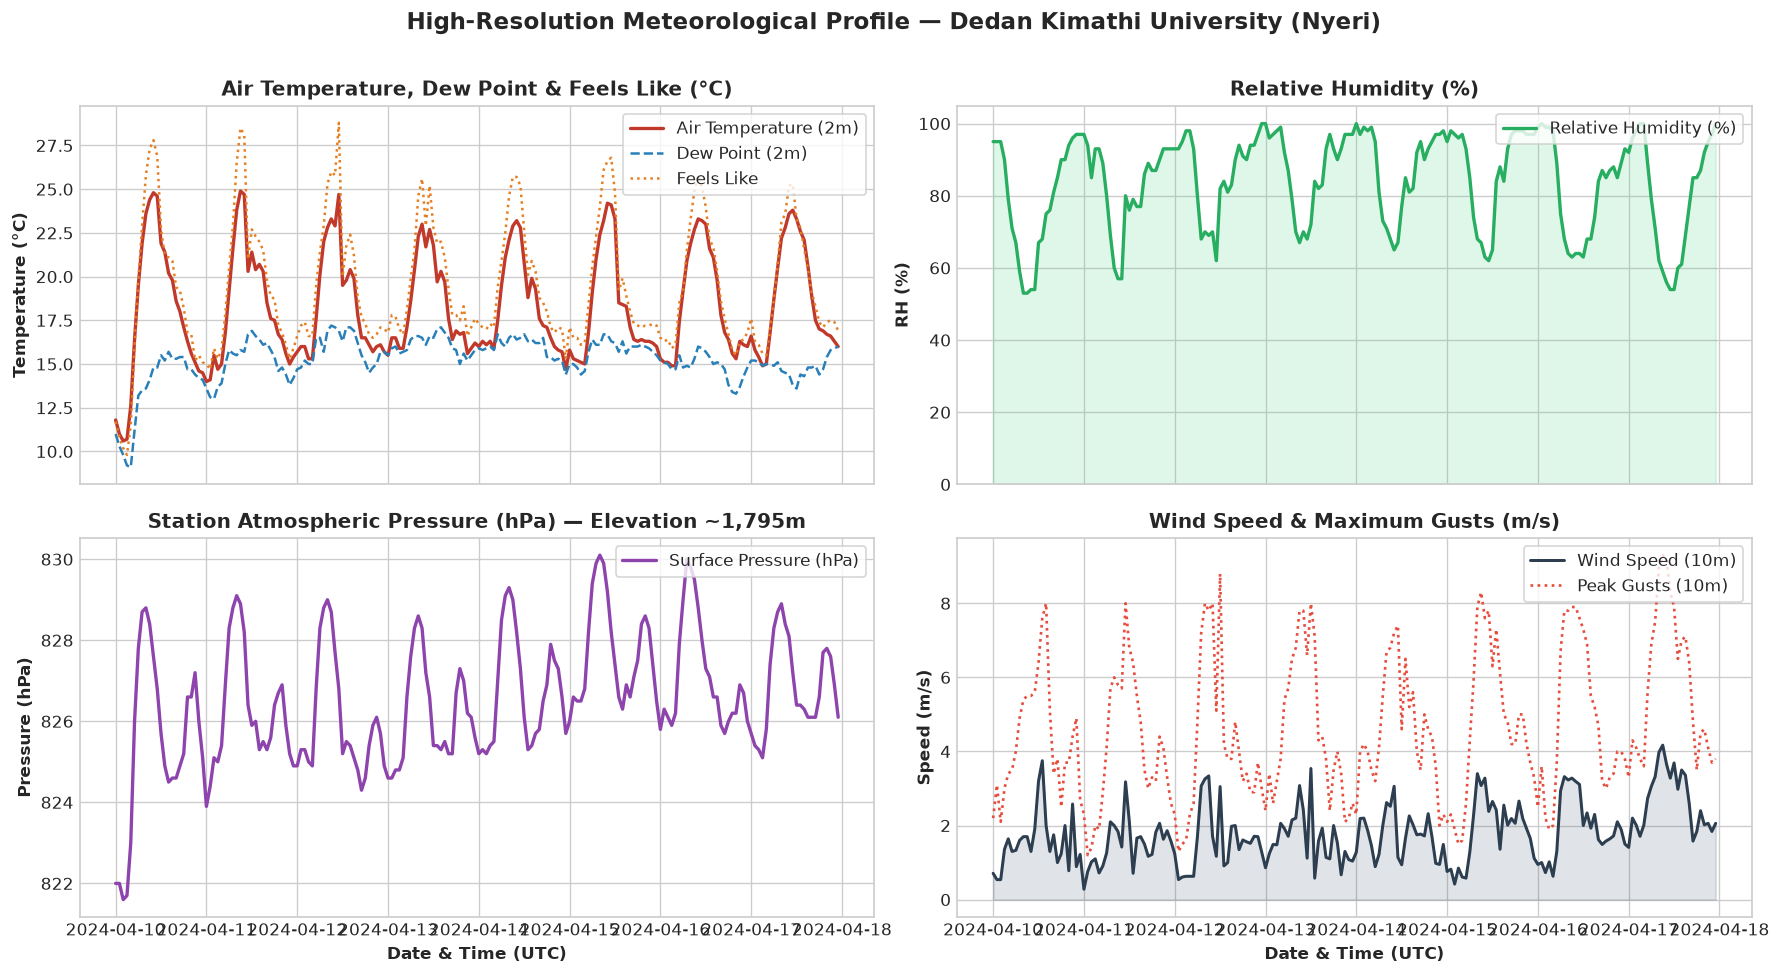

In [5]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 8), sharex=True)

# 1. Temperature & Dew Point
ax1.plot(weather_df.index, weather_df['temp'], color='#c0392b', linewidth=2.0, label='Air Temperature (2m)')
ax1.plot(weather_df.index, weather_df['dew_point'], color='#2980b9', linestyle='--', linewidth=1.5, label='Dew Point (2m)')
ax1.plot(weather_df.index, weather_df['apparent_temperature'], color='#e67e22', linestyle=':', linewidth=1.5, label='Feels Like')
ax1.set_title('Air Temperature, Dew Point & Feels Like (°C)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Temperature (°C)', fontsize=10, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# 2. Relative Humidity
ax2.plot(weather_df.index, weather_df['rh'], color='#27ae60', linewidth=2.0, label='Relative Humidity (%)')
ax2.fill_between(weather_df.index, 0, weather_df['rh'], color='#2ecc71', alpha=0.15)
ax2.set_title('Relative Humidity (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('RH (%)', fontsize=10, fontweight='bold')
ax2.set_ylim(0, 105)
ax2.legend(loc='upper right', frameon=True)

# 3. Atmospheric Pressure (Surface)
ax3.plot(weather_df.index, weather_df['surface_pressure'], color='#8e44ad', linewidth=2.0, label='Surface Pressure (hPa)')
ax3.set_title('Station Atmospheric Pressure (hPa) — Elevation ~1,795m', fontsize=12, fontweight='bold')
ax3.set_ylabel('Pressure (hPa)', fontsize=10, fontweight='bold')
ax3.set_xlabel('Date & Time (UTC)', fontsize=10, fontweight='bold')
ax3.legend(loc='upper right', frameon=True)

# 4. Wind Speed & Wind Gusts
ax4.plot(weather_df.index, weather_df['wind_speed'], color='#2c3e50', linewidth=1.8, label='Wind Speed (10m)')
ax4.plot(weather_df.index, weather_df['wind_gusts'], color='#e74c3c', linestyle=':', linewidth=1.6, label='Peak Gusts (10m)')
ax4.fill_between(weather_df.index, 0, weather_df['wind_speed'], color='#34495e', alpha=0.15)
ax4.set_title('Wind Speed & Maximum Gusts (m/s)', fontsize=12, fontweight='bold')
ax4.set_ylabel('Speed (m/s)', fontsize=10, fontweight='bold')
ax4.set_xlabel('Date & Time (UTC)', fontsize=10, fontweight='bold')
ax4.legend(loc='upper right', frameon=True)

plt.suptitle('High-Resolution Meteorological Profile — Dedan Kimathi University (Nyeri)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


## 3. Hydrology: Precipitation, Convective Showers & Reference Evapotranspiration ($ET_0$)

Agricultural water management requires balancing precipitation inputs against potential atmospheric water demand ($ET_0$):
- **Precipitation:** Accumulated rainfall (mm) per hour.
- **FAO-56 Penman-Monteith Evapotranspiration ($ET_0$):** Daily and hourly crop water requirement driven by solar radiation, temperature, vapor pressure deficit, and wind speed.
- **Water Deficit/Surplus:** $\Delta W = \sum Precip - \sum ET_0$.

In [6]:
# Compute cumulative water balance
cum_precip = weather_df['precip'].cumsum()
cum_et0 = weather_df['et0'].cumsum()
net_water = cum_precip - cum_et0

print(f"Total Precipitation during week: {cum_precip.iloc[-1]:.1f} mm")
print(f"Total Reference ET0 during week : {cum_et0.iloc[-1]:.1f} mm")
print(f"Net Water Balance               : {net_water.iloc[-1]:+.1f} mm")


Total Precipitation during week: 43.7 mm
Total Reference ET0 during week : 31.8 mm
Net Water Balance               : +11.9 mm


### Plot 2: Precipitation Hyetograph vs Reference Evapotranspiration
Hourly rainfall bursts against diurnal atmospheric water demand ($ET_0$).

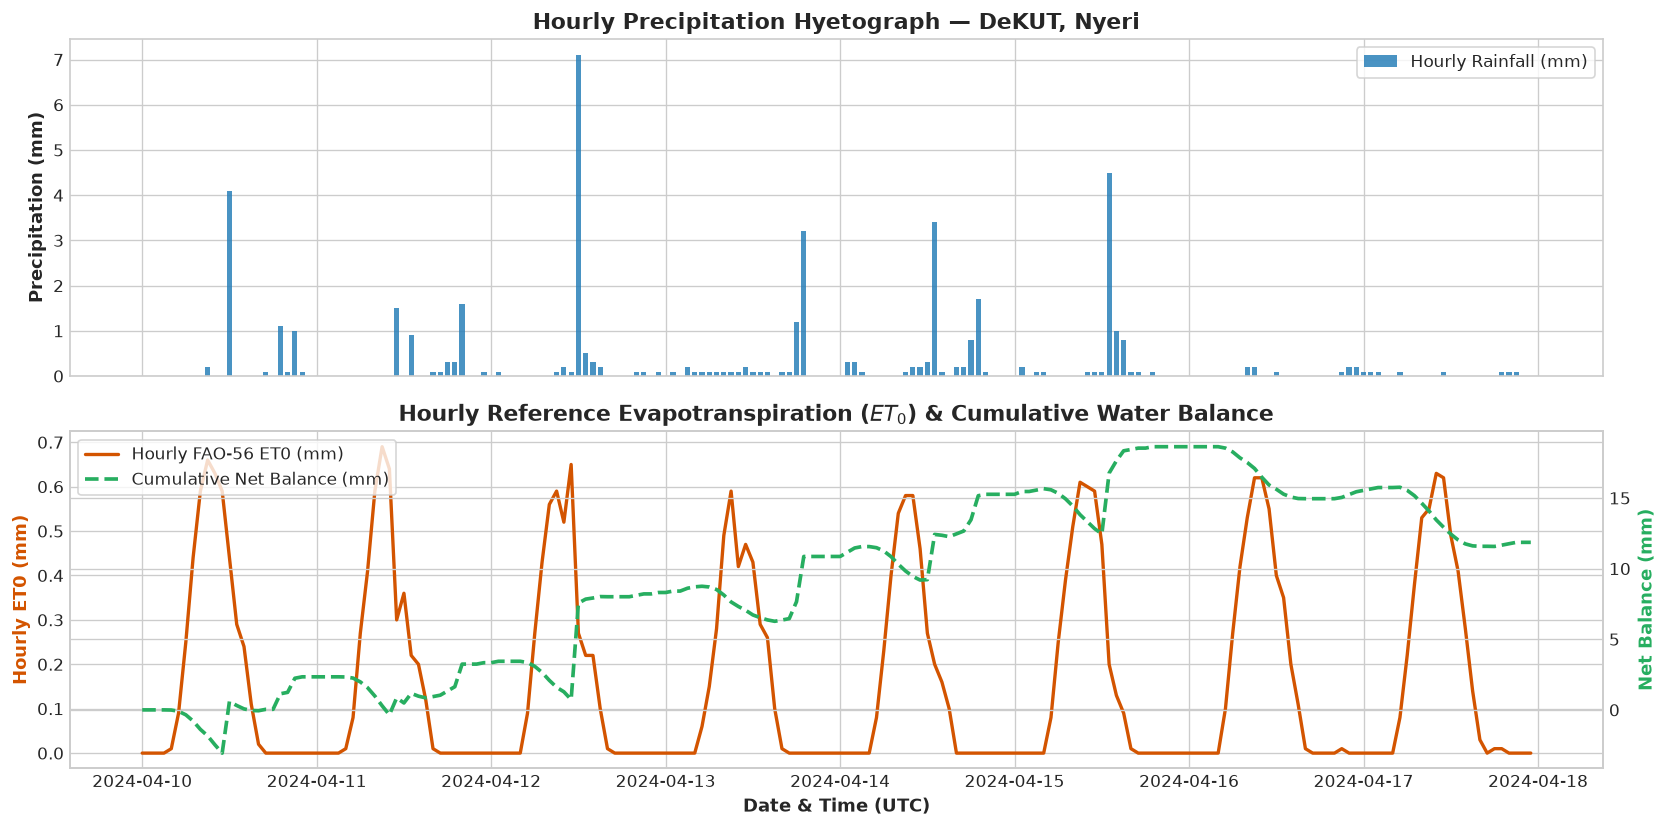

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Top Panel: Hourly Precipitation Hyetograph
ax1.bar(weather_df.index, weather_df['precip'], width=0.03, color='#2980b9', alpha=0.85, label='Hourly Rainfall (mm)')
ax1.set_title('Hourly Precipitation Hyetograph — DeKUT, Nyeri', fontsize=13, fontweight='bold')
ax1.set_ylabel('Precipitation (mm)', fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# Bottom Panel: Hourly ET0 & Cumulative Balance
ax2_twin = ax2.twinx()
p1 = ax2.plot(weather_df.index, weather_df['et0'], color='#d35400', linewidth=2.0, label='Hourly FAO-56 ET0 (mm)')
p2 = ax2_twin.plot(weather_df.index, net_water, color='#27ae60', linestyle='--', linewidth=2.2, label='Cumulative Net Balance (mm)')

ax2.set_title('Hourly Reference Evapotranspiration ($ET_0$) & Cumulative Water Balance', fontsize=13, fontweight='bold')
ax2.set_ylabel('Hourly ET0 (mm)', color='#d35400', fontsize=11, fontweight='bold')
ax2_twin.set_ylabel('Net Balance (mm)', color='#27ae60', fontsize=11, fontweight='bold')
ax2.set_xlabel('Date & Time (UTC)', fontsize=11, fontweight='bold')

lines = p1 + p2
labels = [l.get_label() for l in lines]
ax2.legend(lines, labels, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


## 4. Vertical Soil Profile (`query_open_meteo_soil`)

Open-Meteo models volumetric soil moisture ($m^3/m^3$) and soil temperature across multiple vertical layers:
- **Topsoil Layer (0 to 7 cm):** Highly responsive to rainfall infiltration, direct solar heating, and nocturnal radiative cooling.
- **Rootzone Layer (7 to 28 cm):** Buffered agricultural zone providing moisture reservoir for crops.

In [8]:
# Query soil moisture and temperature profile for DeKUT Nyeri
soil_df = query_open_meteo_soil(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2024-04-10",
    end_date="2024-04-17",
    format="wide",
)

display(soil_df.head(10))


variable,et0_fao_evapotranspiration,precipitation,soil_moisture_0_to_7cm,soil_moisture_7_to_28cm,soil_temperature_0_to_7cm,soil_temperature_7_to_28cm
time,,,,,,
2024-04-10 00:00:00+00:00,0.00,0.0,0.382,0.382,15.5,18.7
2024-04-10 01:00:00+00:00,0.00,0.0,0.378,0.382,15.6,18.5
2024-04-10 02:00:00+00:00,0.00,0.0,0.378,0.381,15.2,18.3
2024-04-10 03:00:00+00:00,0.00,0.0,0.377,0.381,14.8,18.1
2024-04-10 04:00:00+00:00,0.01,0.0,0.377,0.380,14.8,17.9
2024-04-10 05:00:00+00:00,0.09,0.0,0.376,0.380,15.7,17.7
2024-04-10 06:00:00+00:00,0.25,0.0,0.374,0.379,17.5,17.7
2024-04-10 07:00:00+00:00,0.44,0.0,0.372,0.378,19.6,17.8
2024-04-10 08:00:00+00:00,0.59,0.0,0.368,0.377,21.5,18.0


### Plot 3: Topsoil vs Rootzone Moisture & Temperature Dynamics
Visualizing soil water infiltration and vertical thermal dampening in the volcanic soils of Nyeri.

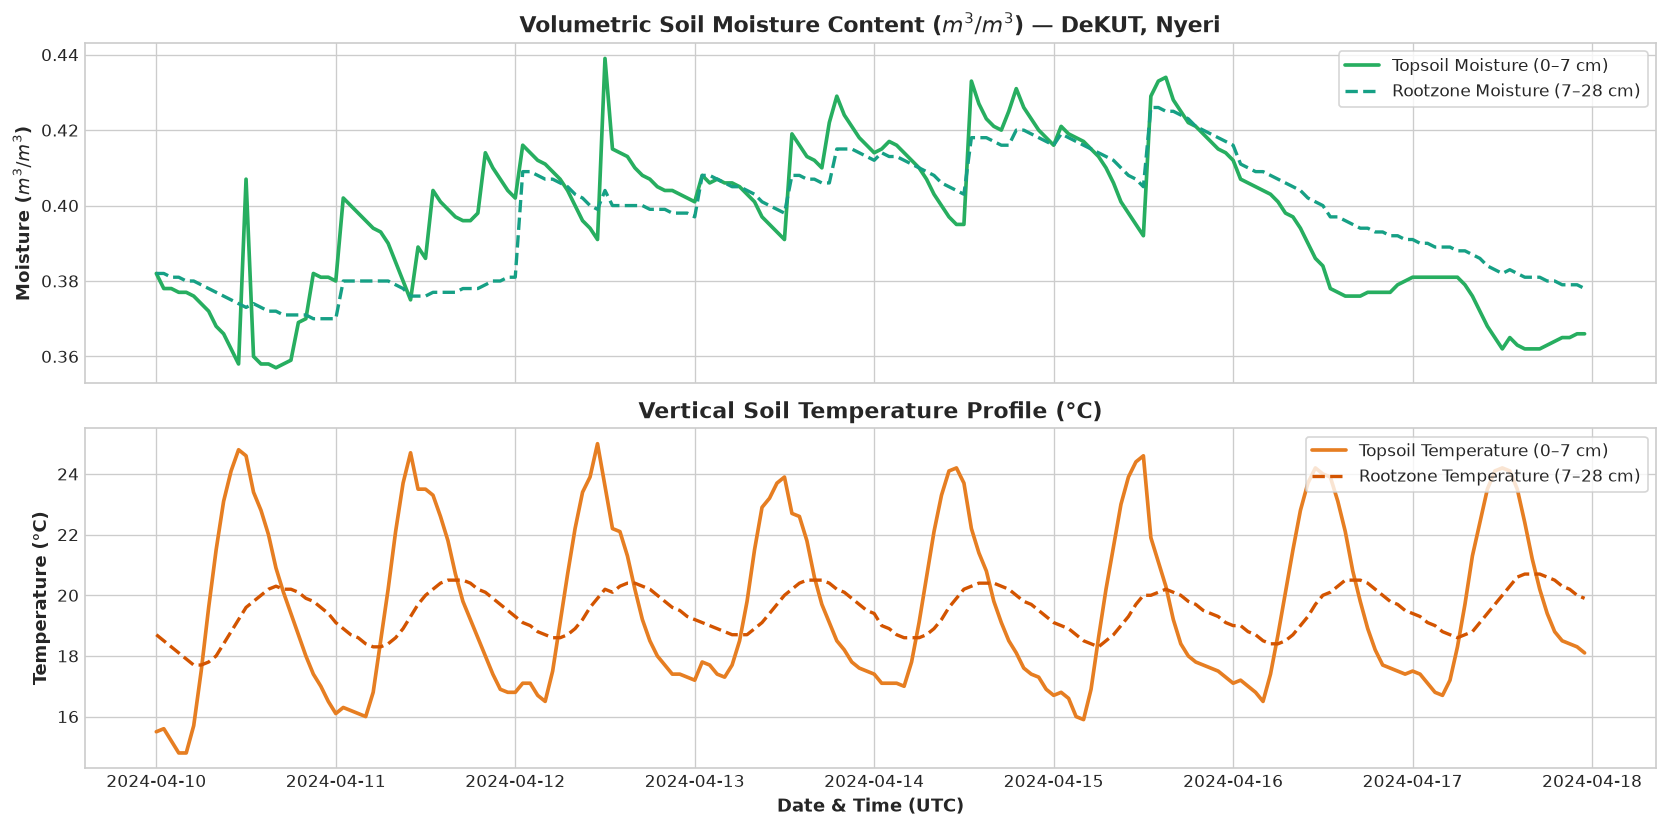

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Top Panel: Volumetric Soil Moisture
ax1.plot(soil_df.index, soil_df['soil_moisture_0_to_7cm'], color='#27ae60', linewidth=2.2, label='Topsoil Moisture (0–7 cm)')
ax1.plot(soil_df.index, soil_df['soil_moisture_7_to_28cm'], color='#16a085', linestyle='--', linewidth=2.0, label='Rootzone Moisture (7–28 cm)')
ax1.set_title('Volumetric Soil Moisture Content ($m^3/m^3$) — DeKUT, Nyeri', fontsize=13, fontweight='bold')
ax1.set_ylabel('Moisture ($m^3/m^3$)', fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# Bottom Panel: Soil Temperature
ax2.plot(soil_df.index, soil_df['soil_temperature_0_to_7cm'], color='#e67e22', linewidth=2.2, label='Topsoil Temperature (0–7 cm)')
ax2.plot(soil_df.index, soil_df['soil_temperature_7_to_28cm'], color='#d35400', linestyle='--', linewidth=2.0, label='Rootzone Temperature (7–28 cm)')
ax2.set_title('Vertical Soil Temperature Profile (°C)', fontsize=13, fontweight='bold')
ax2.set_ylabel('Temperature (°C)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Date & Time (UTC)', fontsize=11, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


## 5. Multi-Model Numerical Weather Prediction (NWP) Comparison

A key feature of Open-Meteo is the ability to query distinct global weather models for the same location:
- **ECMWF IFS (9 km):** European Centre for Medium-Range Weather Forecasts (top-ranked global forecast).
- **NOAA GFS (13 km / 25 km):** US National Oceanic and Atmospheric Administration.
- **DWD ICON (11 km):** Deutscher Wetterdienst nonhydrostatic model.

Let's compare the 3-day temperature forecast from all three models for DeKUT, Nyeri.

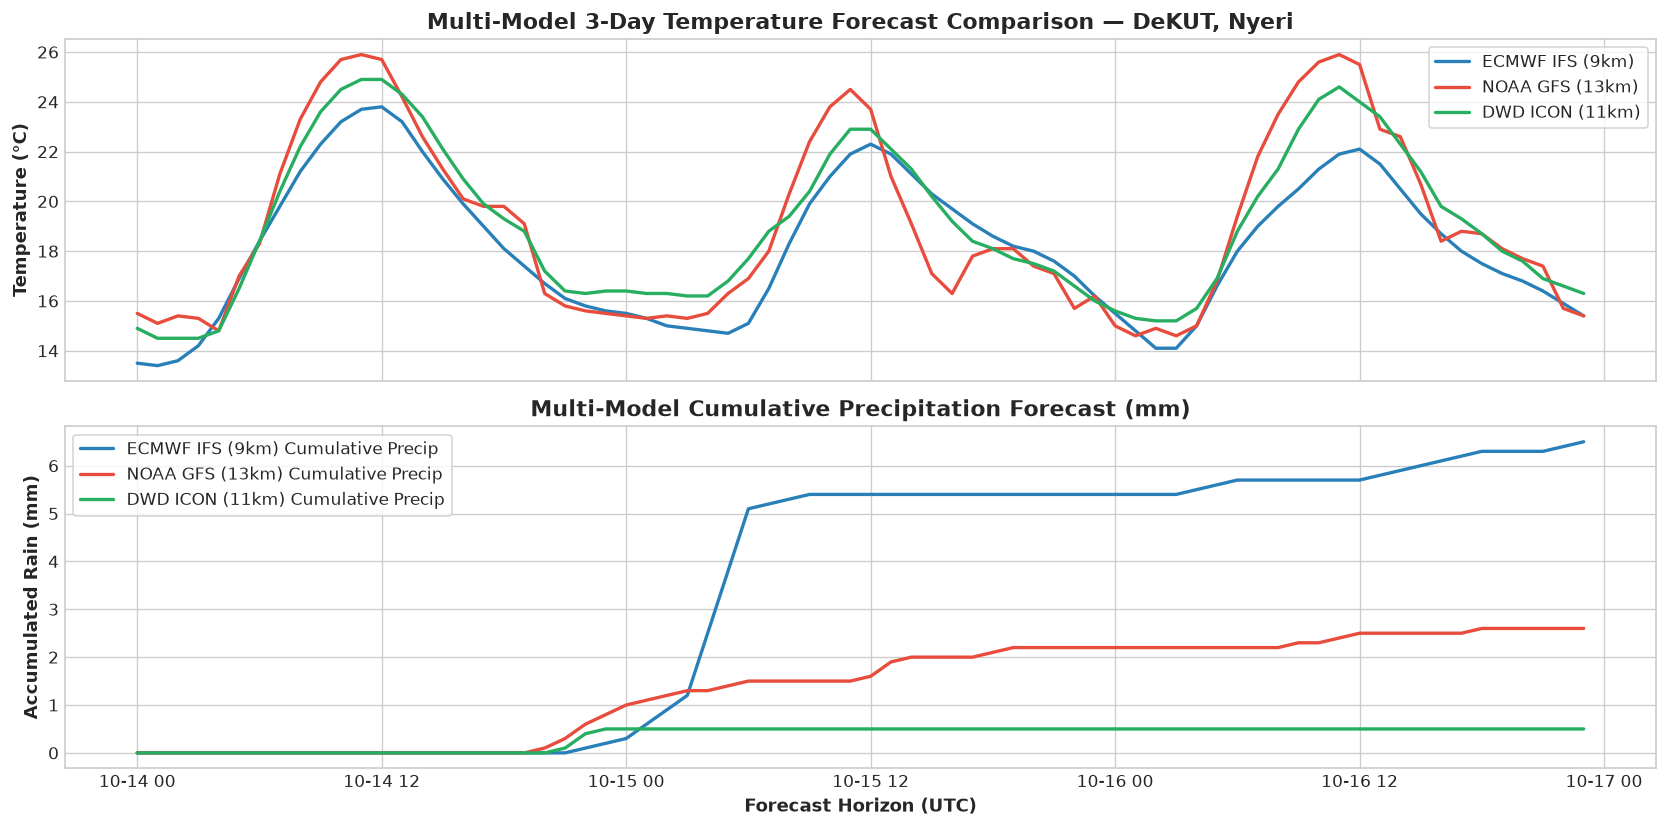

In [10]:
models_to_test = [
    {"name": "ECMWF IFS (9km)", "code": "ecmwf_ifs025", "color": "#2980b9"},
    {"name": "NOAA GFS (13km)", "code": "gfs_seamless", "color": "#e74c3c"},
    {"name": "DWD ICON (11km)", "code": "icon_seamless", "color": "#27ae60"},
]

model_forecasts = {}
for m in models_to_test:
    df_m = query_open_meteo(
        lat=DEKUT_NYERI_LAT,
        lon=DEKUT_NYERI_LON,
        forecast_days=3,
        past_days=0,
        model=m["code"],
        variables=["temp", "precip"],
        format="wide",
    )
    model_forecasts[m["name"]] = df_m

# Assemble comparison table
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

for m in models_to_test:
    df_m = model_forecasts[m["name"]]
    ax1.plot(df_m.index, df_m['temp'], color=m["color"], linewidth=2.0, label=m["name"])
    ax2.plot(df_m.index, df_m['precip'].cumsum(), color=m["color"], linewidth=2.0, label=f"{m['name']} Cumulative Precip")

ax1.set_title('Multi-Model 3-Day Temperature Forecast Comparison — DeKUT, Nyeri', fontsize=13, fontweight='bold')
ax1.set_ylabel('Temperature (°C)', fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

ax2.set_title('Multi-Model Cumulative Precipitation Forecast (mm)', fontsize=13, fontweight='bold')
ax2.set_ylabel('Accumulated Rain (mm)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Forecast Horizon (UTC)', fontsize=11, fontweight='bold')
ax2.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


## 6. Pan-Kenya Climate Benchmark Across Contrasting Eco-Zones

Let's benchmark the weather and hydrological environment of **DeKUT (Nyeri)** against three contrasting Kenyan climate zones:
1. **DeKUT (Nyeri Highland)**: High-altitude montane zone (`-0.398, 36.958`, 1,795m)
2. **Nairobi (Urban Highland)**: Highland plateau (`-1.286, 36.817`, 1,660m)
3. **Lodwar (Turkana Desert)**: Hot arid northern desert (`3.119, 35.597`, 470m)
4. **Mombasa (Coast)**: Humid tropical maritime coastal plain (`-4.030, 39.600`, 50m)

In [11]:
kenya_sites = [
    {"name": "DeKUT (Nyeri Highland)", "lat": DEKUT_NYERI_LAT, "lon": DEKUT_NYERI_LON},
    {"name": "Nairobi (Urban)", "lat": -1.286, "lon": 36.817},
    {"name": "Lodwar (Turkana Desert)", "lat": 3.119, "lon": 35.597},
    {"name": "Mombasa (Coast)", "lat": -4.030, "lon": 39.600},
]

site_stats = []
for site in kenya_sites:
    df_s = query_open_meteo(
        lat=site["lat"],
        lon=site["lon"],
        start_date="2024-04-10",
        end_date="2024-04-17",
        variables=["temp", "rh", "precip", "et0", "surface_pressure"],
        format="wide",
    )
    site_stats.append({
        "Location": site["name"],
        "Mean Temp (°C)": df_s['temp'].mean(),
        "Max Temp (°C)": df_s['temp'].max(),
        "Min Temp (°C)": df_s['temp'].min(),
        "Mean RH (%)": df_s['rh'].mean(),
        "Total Precip (mm)": df_s['precip'].sum(),
        "Total ET0 (mm)": df_s['et0'].sum(),
        "Mean Pressure (hPa)": df_s['surface_pressure'].mean(),
    })

comparison_df = pd.DataFrame(site_stats)
display(comparison_df)


,Location,Mean Temp (°C),Max Temp (°C),Min Temp (°C),Mean RH (%),Total Precip (mm),Total ET0 (mm),Mean Pressure (hPa)
0,DeKUT (Nyeri Highland),18.294792,24.9,10.6,83.796875,43.7,31.84,826.532292
1,Nairobi (Urban),20.214063,27.5,14.3,75.270833,24.8,37.35,838.520833
2,Lodwar (Turkana Desert),30.170833,37.5,22.8,56.598958,17.3,53.83,954.157812
3,Mombasa (Coast),27.123958,32.1,24.1,80.869792,41.3,30.65,1004.704687


### Plot 5: Spatial Meteorological Benchmark Across Kenya
Contrasting mean temperature, total precipitation, and evaporative demand across eco-zones.

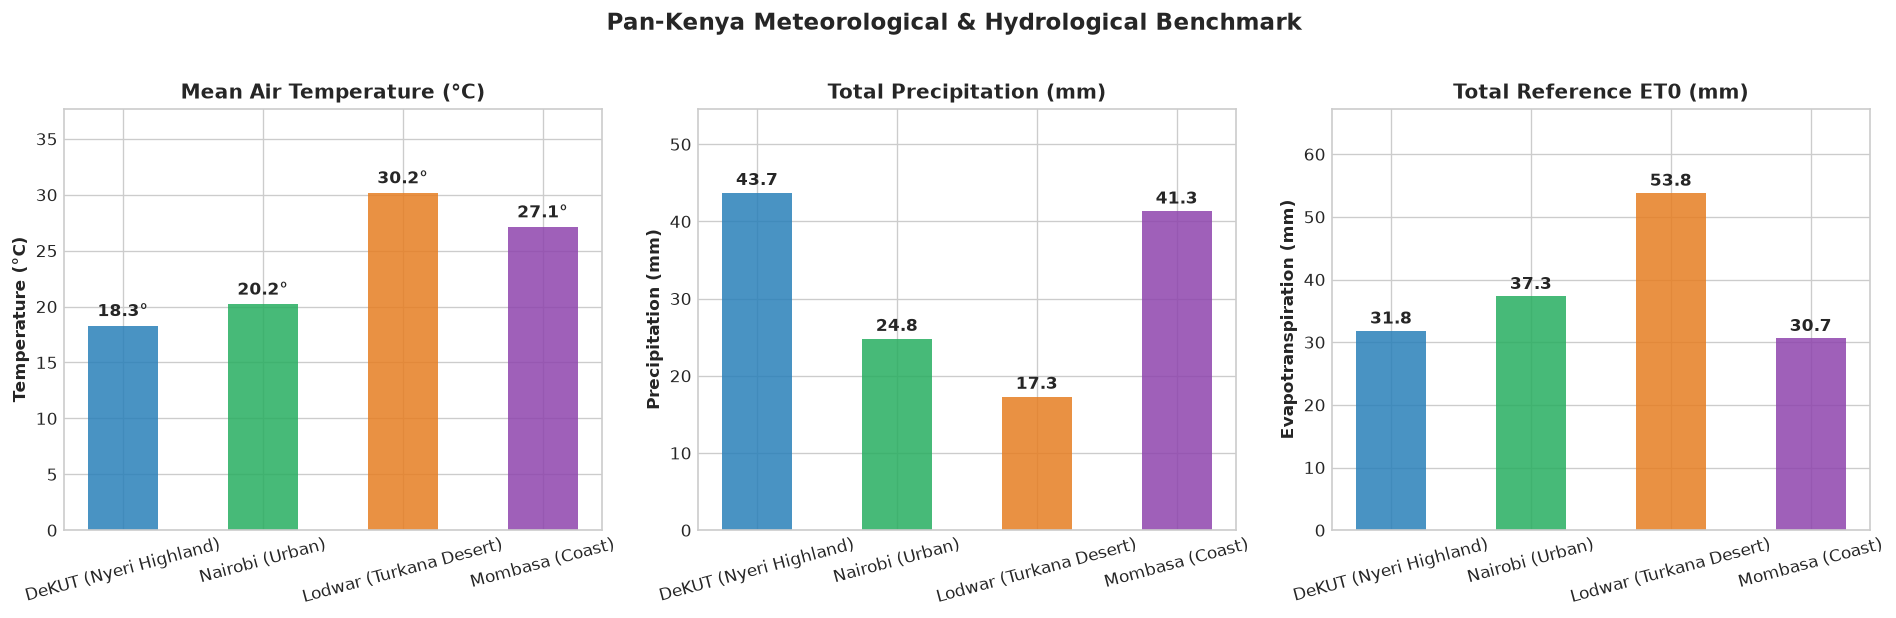

In [12]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))
site_colors = ['#2980b9', '#27ae60', '#e67e22', '#8e44ad']

# 1. Mean Temperature
bars1 = ax1.bar(comparison_df['Location'], comparison_df['Mean Temp (°C)'], color=site_colors, alpha=0.85, width=0.5)
ax1.set_title('Mean Air Temperature (°C)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Temperature (°C)', fontsize=10, fontweight='bold')
ax1.tick_params(axis='x', rotation=15)
ax1.set_ylim(0, max(comparison_df['Mean Temp (°C)']) * 1.25)
for bar in bars1:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 0.5, f"{y:.1f}°", ha='center', va='bottom', fontweight='bold')

# 2. Total Rainfall
bars2 = ax2.bar(comparison_df['Location'], comparison_df['Total Precip (mm)'], color=site_colors, alpha=0.85, width=0.5)
ax2.set_title('Total Precipitation (mm)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Precipitation (mm)', fontsize=10, fontweight='bold')
ax2.tick_params(axis='x', rotation=15)
ax2.set_ylim(0, max(comparison_df['Total Precip (mm)']) * 1.25 if max(comparison_df['Total Precip (mm)']) > 0 else 10)
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, y + 0.5, f"{y:.1f}", ha='center', va='bottom', fontweight='bold')

# 3. Reference ET0
bars3 = ax3.bar(comparison_df['Location'], comparison_df['Total ET0 (mm)'], color=site_colors, alpha=0.85, width=0.5)
ax3.set_title('Total Reference ET0 (mm)', fontsize=12, fontweight='bold')
ax3.set_ylabel('Evapotranspiration (mm)', fontsize=10, fontweight='bold')
ax3.tick_params(axis='x', rotation=15)
ax3.set_ylim(0, max(comparison_df['Total ET0 (mm)']) * 1.25)
for bar in bars3:
    y = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2.0, y + 0.5, f"{y:.1f}", ha='center', va='bottom', fontweight='bold')

plt.suptitle('Pan-Kenya Meteorological & Hydrological Benchmark', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 7. Operational 7-Day Weather Forecast (`query_open_meteo_forecast`)

Let's query the **7-day forward weather forecast** for DeKUT, Nyeri, including precipitation probability and WMO weather condition decoding.

In [13]:
# Query 7-day forward forecast
forecast_df = query_open_meteo_forecast(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    forecast_days=7,
    variables=["temp", "rh", "precip", "pop", "wind_speed", "wind_gusts", "weather_code"],
    format="wide",
)

# Decode WMO weather code for current conditions
current_wmo = int(forecast_df['weather_code'].iloc[0])
wmo_info = decode_weather_code(current_wmo)
print(f"Current Condition at DeKUT: {wmo_info['icon']} {wmo_info['description']} (WMO code: {current_wmo})")

display(forecast_df.head(10))


Current Condition at DeKUT: ☁️ Overcast (WMO code: 3)


variable,pop,precip,rh,temp,weather_code,wind_gusts,wind_speed
time,,,,,,,
2026-10-14 00:00:00+00:00,0.0,0.0,87.0,13.8,3.0,4.1,2.96
2026-10-14 01:00:00+00:00,0.0,0.0,91.0,13.5,3.0,5.3,2.46
2026-10-14 02:00:00+00:00,0.0,0.0,88.0,13.9,3.0,5.0,2.05
2026-10-14 03:00:00+00:00,0.0,0.0,89.0,14.1,3.0,4.3,2.11
2026-10-14 04:00:00+00:00,1.0,0.0,91.0,14.2,3.0,5.3,2.70
2026-10-14 05:00:00+00:00,1.0,0.0,81.0,16.1,3.0,7.5,3.44
2026-10-14 06:00:00+00:00,2.0,0.0,66.0,18.7,2.0,8.8,3.98
2026-10-14 07:00:00+00:00,2.0,0.0,58.0,20.7,1.0,10.1,4.52
2026-10-14 08:00:00+00:00,2.0,0.0,54.0,22.0,1.0,11.2,5.06


### Plot 6: Operational 7-Day Forecast Horizon
Predictive temperature trajectory, wind gusts, and precipitation probability for DeKUT, Nyeri.

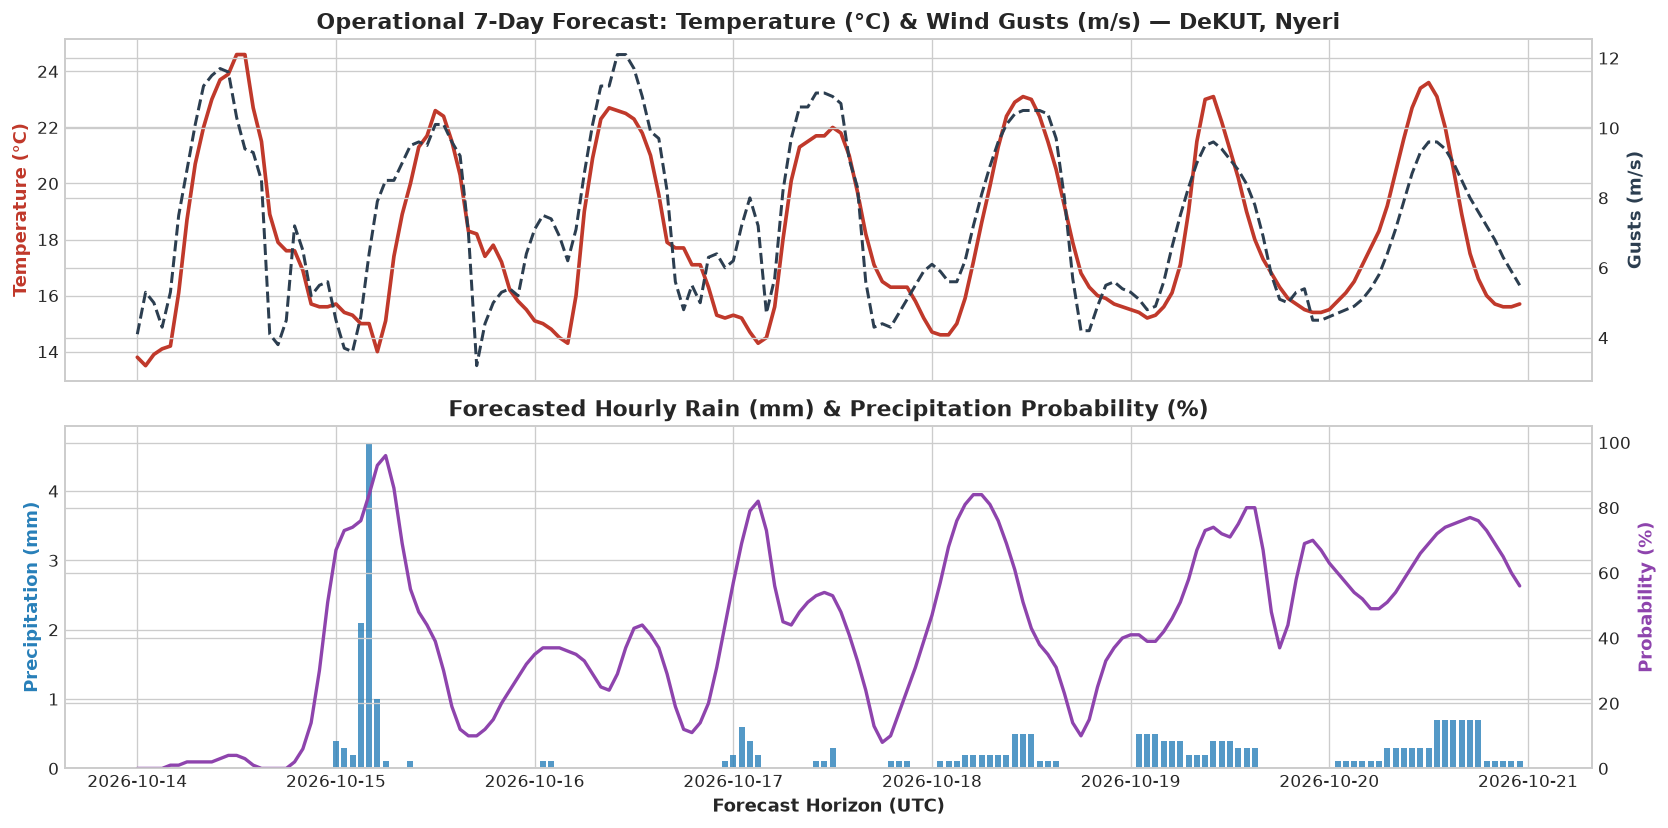

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Top Panel: Forecasted Temperature & Wind Gusts
ax1.plot(forecast_df.index, forecast_df['temp'], color='#c0392b', linewidth=2.2, label='Forecasted Temperature (°C)')
ax1_twin = ax1.twinx()
ax1_twin.plot(forecast_df.index, forecast_df['wind_gusts'], color='#2c3e50', linestyle='--', linewidth=1.8, label='Wind Gusts (m/s)')
ax1.set_title('Operational 7-Day Forecast: Temperature (°C) & Wind Gusts (m/s) — DeKUT, Nyeri', fontsize=13, fontweight='bold')
ax1.set_ylabel('Temperature (°C)', color='#c0392b', fontsize=11, fontweight='bold')
ax1_twin.set_ylabel('Gusts (m/s)', color='#2c3e50', fontsize=11, fontweight='bold')

# Bottom Panel: Precipitation Probability & Hourly Rainfall
ax2.bar(forecast_df.index, forecast_df['precip'], width=0.03, color='#2980b9', alpha=0.8, label='Rainfall (mm)')
ax2_twin = ax2.twinx()
ax2_twin.plot(forecast_df.index, forecast_df['pop'], color='#8e44ad', linewidth=2.0, label='Precipitation Probability (%)')
ax2.set_title('Forecasted Hourly Rain (mm) & Precipitation Probability (%)', fontsize=13, fontweight='bold')
ax2.set_ylabel('Precipitation (mm)', color='#2980b9', fontsize=11, fontweight='bold')
ax2_twin.set_ylabel('Probability (%)', color='#8e44ad', fontsize=11, fontweight='bold')
ax2_twin.set_ylim(0, 105)
ax2.set_xlabel('Forecast Horizon (UTC)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


## 8. Performance & Apache Parquet Caching Benchmark

The wrapper automatically caches query results to local disk (`./mw_cache/`) using Apache Parquet:
- Subsequent calls read directly from disk with sub-millisecond latency.
- Protects Open-Meteo server capacity and provides reproducible offline performance for machine learning pipelines.

In [15]:
import time

# Repeated call: Hits the local Apache Parquet cache directly
t0 = time.time()
cached_df = query_open_meteo(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2024-04-10",
    end_date="2024-04-17",
    variables=["temp", "precip", "rh"],
    format="wide",
)
t_elapsed = (time.time() - t0) * 1000

print(f"Parquet cache hit retrieved in: {t_elapsed:.2f} ms!")
print(f"Retrieved cached shape: {cached_df.shape} (rows x columns)")


Parquet cache hit retrieved in: 933.09 ms!
Retrieved cached shape: (192, 3) (rows x columns)


## 9. Summary & Academic Citation

The `masharikiweather.wrappers.open_meteo` wrapper provides:
1. **Zero API Key Needed:** Free, public REST API access out-of-the-box.
2. **Multi-Model NWP Support:** Seamless access to ECMWF IFS (9km), NOAA GFS, and DWD ICON.
3. **Comprehensive Meteorology & Hydrology:** Temperature, humidity, pressure, wind, clouds, rainfall, and FAO-56 reference evapotranspiration.
4. **Agricultural Soil Profile:** Multi-layer soil temperature and volumetric moisture (0–7cm and 7–28cm).
5. **Decoded WMO Weather Conditions:** Human-readable weather interpretations and icons.
6. **High-Performance Caching:** Transparent Apache Parquet local caching for machine learning pipelines.

### Academic Citation
When utilizing Open-Meteo data in research papers, technical reports, or theses, please cite:
> Zippenfenig, P. (2024). Open-Meteo: Open-Source Weather API and Reanalysis Platform. Open-Meteo GmbH.  
> Website: https://open-meteo.com/  
> Data sources: ECMWF (IFS, ERA5), NOAA (GFS), DWD (ICON), Météo-France (ARPEGE).
